In [1]:
import re
from pathlib import Path
import numpy as np
import pandas as pd
from google.colab import drive

drive.mount('/content/drive')

# === CAMINHOS NO GOOGLE DRIVE ===
PASTA_PROJETO = Path("/content/drive/MyDrive")  # <-- Ajuste se salvou em subpasta
ARQUIVO_ENTRADA = PASTA_PROJETO / "transcrições.csv"
PASTA_RESULTADOS = PASTA_PROJETO / "resultados_etapa2"
PASTA_RESULTADOS.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(ARQUIVO_ENTRADA)

# Dicionário de expansão de contrações para evitar fragmentos ("don", "ve", "ll")
CONTRACTIONS = {
    r"\bdon't\b": "do not", r"\bdoesn't\b": "does not", r"\bdidn't\b": "did not",
    r"\bcan't\b": "cannot", r"\bwon't\b": "will not", r"\bisn't\b": "is not",
    r"\baren't\b": "are not", r"\bwasn't\b": "was not", r"\bweren't\b": "were not",
    r"\bi'm\b": "i am", r"\byou're\b": "you are", r"\bhe's\b": "he is",
    r"\bshe's\b": "she is", r"\bit's\b": "it is", r"\bwe're\b": "we are",
    r"\bthey're\b": "they are", r"\bthat's\b": "that is", r"\bwhat's\b": "what is",
    r"\bhere's\b": "here is", r"\bthere's\b": "there is", r"\blet's\b": "let us",
    r"\bi've\b": "i have", r"\byou've\b": "you have", r"\bwe've\b": "we have",
    r"\bthey've\b": "they have", r"\bi'll\b": "i will", r"\byou'll\b": "you will",
    r"\bwe'll\b": "we will", r"\bi'd\b": "i would", r"\byou'd\b": "you would",
    r"\bgonna\b": "going to", r"\bwanna\b": "want to", r"\bgotta\b": "got to"
}

def limpar_transcricao(texto):
    if not isinstance(texto, str):
        return ""
    t = texto.lower()
    # Remove símbolos musicais e alucinações residuais de encerramento
    t = re.sub(r'[🎵♪©]', ' ', t)
    t = re.sub(
        r'\b(thanks for watching|thank you for watching|please subscribe|outro music|bf-watch tv \d+)\b',
        ' ', t
    )
    for padrao, substituto in CONTRACTIONS.items():
        t = re.sub(padrao, substituto, t)
    # Remove sufixos ordinais isolados (ex: 14th -> espaço) e pontuação
    t = re.sub(r'\b\d+(st|nd|rd|th)\b', ' ', t)
    t = re.sub(r'[^a-z\s]', ' ', t)
    # Colapsa repetições consecutivas >= 3x da mesma palavra (ex: "yeah yeah yeah" -> "yeah")
    t = re.sub(r'\b(\w+)(?:\s+\1){2,}\b', r'\1', t)
    t = re.sub(r'\s+', ' ', t).strip()
    return t

df["texto_limpo"] = df["transcricao"].apply(limpar_transcricao)
df["qtd_palavras_limpa"] = df["texto_limpo"].apply(lambda x: len(x.split()) if x else 0)
df["palavras_por_segundo"] = np.where(
    df["duracao_seg"] > 0,
    (df["qtd_palavras_limpa"] / df["duracao_seg"]).round(2),
    np.nan
)

# Filtra apenas vídeos com discurso substantivo (>= 5 palavras válidas)
df_analise = df[(df["status"] == "sucesso") & (df["qtd_palavras_limpa"] >= 5)].copy()

# Flag para identificar eventuais roteiros repostados com início idêntico
df_analise["prefixo_roteiro"] = df_analise["texto_limpo"].str[:80]
df_analise["is_repost_roteiro"] = df_analise.duplicated("prefixo_roteiro", keep="first")
df_analise.drop(columns=["prefixo_roteiro"], inplace=True)

arquivo_limpo = PASTA_RESULTADOS / "transcricoes_limpas.csv"
df_analise.to_csv(arquivo_limpo, index=False, encoding="utf-8-sig")

print(f"Total bruto no CSV: {len(df)} vídeos")
print(f"Corpus analítico válido (>= 5 palavras): {len(df_analise)} vídeos")
print(f"Total de palavras úteis no corpus: {df_analise['qtd_palavras_limpa'].sum()}")
print(f"Taxa média de fala: {df_analise['palavras_por_segundo'].mean():.2f} palavras/segundo")
print(f"Arquivo salvo em: {arquivo_limpo}")

Mounted at /content/drive
Total bruto no CSV: 254 vídeos
Corpus analítico válido (>= 5 palavras): 212 vídeos
Total de palavras úteis no corpus: 19999
Taxa média de fala: 2.26 palavras/segundo
Arquivo salvo em: /content/drive/MyDrive/resultados_etapa2/transcricoes_limpas.csv


In [2]:
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer, ENGLISH_STOP_WORDS

# Remove stopwords padrão + marcadores de oralidade informal que mascaram o léxico temático
MARCADORES_ORALIDADE = {
    "like", "just", "yeah", "oh", "uh", "um", "ah", "ha", "wow", "whoa", "hey",
    "guys", "okay", "ok", "yes", "no", "well", "now", "really", "right", "know",
    "got", "get", "go", "going", "come", "came", "let", "look", "see", "say",
    "said", "thing", "things", "way", "make", "made", "want", "need", "think",
    "one", "two", "little", "big", "good", "great", "super", "much", "time",
    "day", "today", "actually", "literally", "kind", "sort", "lot", "also",
    "even", "still", "back", "take", "put", "use", "using", "used", "feel",
    "try", "trying", "wait", "watch", "did", "doing", "man", "bro", "baby", "mom", "dad"
}
STOPWORDS_FINAIS = list(set(ENGLISH_STOP_WORDS).union(MARCADORES_ORALIDADE))

def extrair_ngramas(corpus, n_gram_range=(1, 1), top_k=25):
    vec_count = CountVectorizer(
        ngram_range=n_gram_range,
        stop_words=STOPWORDS_FINAIS,
        token_pattern=r"\b[a-z]{2,}\b"
    )
    X_count = vec_count.fit_transform(corpus)

    vec_tfidf = TfidfVectorizer(
        ngram_range=n_gram_range,
        stop_words=STOPWORDS_FINAIS,
        token_pattern=r"\b[a-z]{2,}\b"
    )
    X_tfidf = vec_tfidf.fit_transform(corpus)

    termos = vec_count.get_feature_names_out()
    ocorrencias = np.asarray(X_count.sum(axis=0)).ravel()
    videos_presentes = np.asarray((X_count > 0).sum(axis=0)).ravel()
    tfidf_medio = np.asarray(X_tfidf.mean(axis=0)).ravel()

    df_res = pd.DataFrame({
        "termo": termos,
        "ocorrencias": ocorrencias,
        "videos_presentes": videos_presentes,
        "pct_videos": (videos_presentes / len(corpus) * 100).round(2),
        "tfidf_medio": tfidf_medio.round(5)
    }).sort_values(["ocorrencias", "tfidf_medio"], ascending=False)

    return df_res.head(top_k)

df_unigramas = extrair_ngramas(df_analise["texto_limpo"], (1, 1), top_k=30)
df_bigramas  = extrair_ngramas(df_analise["texto_limpo"], (2, 2), top_k=25)
df_trigramas = extrair_ngramas(df_analise["texto_limpo"], (3, 3), top_k=20)

# Exporta tabelas consolidadas para o artigo
df_unigramas.to_csv(PASTA_RESULTADOS / "top_unigramas.csv", index=False, encoding="utf-8-sig")
df_bigramas.to_csv(PASTA_RESULTADOS / "top_bigramas.csv", index=False, encoding="utf-8-sig")
df_trigramas.to_csv(PASTA_RESULTADOS / "top_trigramas.csv", index=False, encoding="utf-8-sig")

print("=== TOP 15 UNIGRAMAS ===")
display(df_unigramas.head(15))

print("\n=== TOP 15 BIGRAMAS ===")
display(df_bigramas.head(15))

print("\n=== TOP 12 TRIGRAMAS ===")
display(df_trigramas.head(12))

=== TOP 15 UNIGRAMAS ===


,termo,ocorrencias,videos_presentes,pct_videos,tfidf_medio
2122,skin,59,17,8.02,0.01875
1403,love,48,31,14.62,0.01853
1580,new,41,27,12.74,0.01692
500,cool,29,24,11.32,0.01208
2360,thank,28,22,10.38,0.01874
1352,life,27,17,8.02,0.01032
198,best,26,22,10.38,0.01150
2248,stop,24,17,8.02,0.01274
2619,world,23,19,8.96,0.01345
1890,ready,23,20,9.43,0.01117



=== TOP 15 BIGRAMAS ===


,termo,ocorrencias,videos_presentes,pct_videos,tfidf_medio
5623,water gel,9,5,2.36,0.00389
2797,king kings,8,4,1.89,0.00480
65,ad nintendo,8,8,3.77,0.00430
515,boost water,8,5,2.36,0.00345
2563,hydro boost,7,3,1.42,0.00349
4384,ryan world,6,5,2.36,0.00764
3782,peach showtime,6,2,0.94,0.00318
4044,princess peach,6,2,0.94,0.00318
521,born roma,6,1,0.47,0.00254
5794,world movie,5,5,2.36,0.00676



=== TOP 12 TRIGRAMAS ===


,termo,ocorrencias,videos_presentes,pct_videos,tfidf_medio
529,boost water gel,8,5,2.36,0.00365
4135,princess peach showtime,6,2,0.94,0.00344
4480,ryan world movie,5,5,2.36,0.00729
2590,hydra boost water,5,3,1.42,0.00233
3574,neutrogena hydra boost,5,3,1.42,0.00233
4042,playing princess peach,4,2,0.94,0.00223
2792,juicy hydrated skin,4,3,1.42,0.00211
2906,la roche posay,4,1,0.47,0.00191
3035,lightning thunder thunder,3,1,0.47,0.00254
2493,home home home,3,1,0.47,0.00239


In [3]:
LEXICO_CATEGORIAS = {
    "Apelo Afetivo & Entusiasmo": [
        "love", "favorite", "obsessed", "amazing", "best", "perfect",
        "awesome", "cool", "excited", "fun", "delicious", "yummy", "cute"
    ],
    "Brinquedos, Moda & Lifestyle": [
        "toy", "doll", "collection", "outfit", "clothes", "shoes",
        "snack", "water", "drink", "candy", "family", "friends"
    ],
    "Call-to-Action & Comércio": [
        "link", "bio", "shop", "buy", "code", "discount", "order",
        "store", "target", "walmart", "amazon", "available", "app", "download", "check out"
    ],
    "Games, Tech & Entretenimento": [
        "nintendo", "switch", "game", "playing", "peach", "showtime",
        "mario", "movie", "theater", "robot", "miko", "alienware", "roblox", "elden ring"
    ],
    "Skincare & Beleza": [
        "skin", "hydrated", "hydration", "glow", "water gel", "hydro boost",
        "neutrogena", "la roche posay", "moisturizer", "spf", "sunscreen", "lip", "hair", "routine", "blush"
    ],
    "Divulgação & Patrocínio Explícito": [
        "ad", "sponsored", "partner", "partnering", "partnership",
        "collab", "collaboration", "gifted", "ambassador", "work with"
    ]
}

resumo_categorias = []

for categoria, termos in LEXICO_CATEGORIAS.items():
    padrao = r'\b(?:' + '|'.join(re.escape(t) for t in termos) + r')\b'
    contagens = df_analise["texto_limpo"].apply(lambda x: len(re.findall(padrao, x)))
    df_analise[f"cat_{categoria}"] = contagens

    qtd_videos = (contagens > 0).sum()
    total_ocorrencias = contagens.sum()

    # Pega um trecho representativo onde a categoria aparece com mais força
    idx_top = contagens.idxmax()
    exemplo_id = df_analise.loc[idx_top, "id_post"] if qtd_videos > 0 else "-"
    exemplo_txt = df_analise.loc[idx_top, "transcricao"][:140] + "..." if qtd_videos > 0 else "-"

    resumo_categorias.append({
        "Eixo_Discursivo": categoria,
        "Videos_Presentes": qtd_videos,
        "Pct_Corpus": round(qtd_videos / len(df_analise) * 100, 1),
        "Total_Mencoes": total_ocorrencias,
        "ID_Exemplo": exemplo_id,
        "Trecho_Exemplo": exemplo_txt
    })

df_categorias = pd.DataFrame(resumo_categorias).sort_values("Pct_Corpus", ascending=False)
df_categorias.to_csv(PASTA_RESULTADOS / "tabela_eixos_discursivos.csv", index=False, encoding="utf-8-sig")

print("=== PREVALÊNCIA DOS EIXOS DISCURSIVOS NO ÁUDIO PUBLICITÁRIO ===")
display(df_categorias)

=== PREVALÊNCIA DOS EIXOS DISCURSIVOS NO ÁUDIO PUBLICITÁRIO ===


,Eixo_Discursivo,Videos_Presentes,Pct_Corpus,Total_Mencoes,ID_Exemplo,Trecho_Exemplo
0,Apelo Afetivo & Entusiasmo,92,43.4,202,3038375855530297417,So I went thrifting today and I'm going to be ...
1,"Brinquedos, Moda & Lifestyle",48,22.6,90,3436053816175570371,"Alright, so a lot of you have been asking abou..."
2,Call-to-Action & Comércio,36,17.0,67,3536094421450273512,It's January 1st and I'm rotting on my parents...
3,"Games, Tech & Entretenimento",35,16.5,143,3338246027604885665,"This is an ad for Nintendo. Yay, we're include..."
4,Skincare & Beleza,30,14.2,180,3502075571843114475,So I have a big juicy secret. And when I tell ...
5,Divulgação & Patrocínio Explícito,17,8.0,19,3241657674973532257,This is an ad for Miko Robot. What's that? I k...


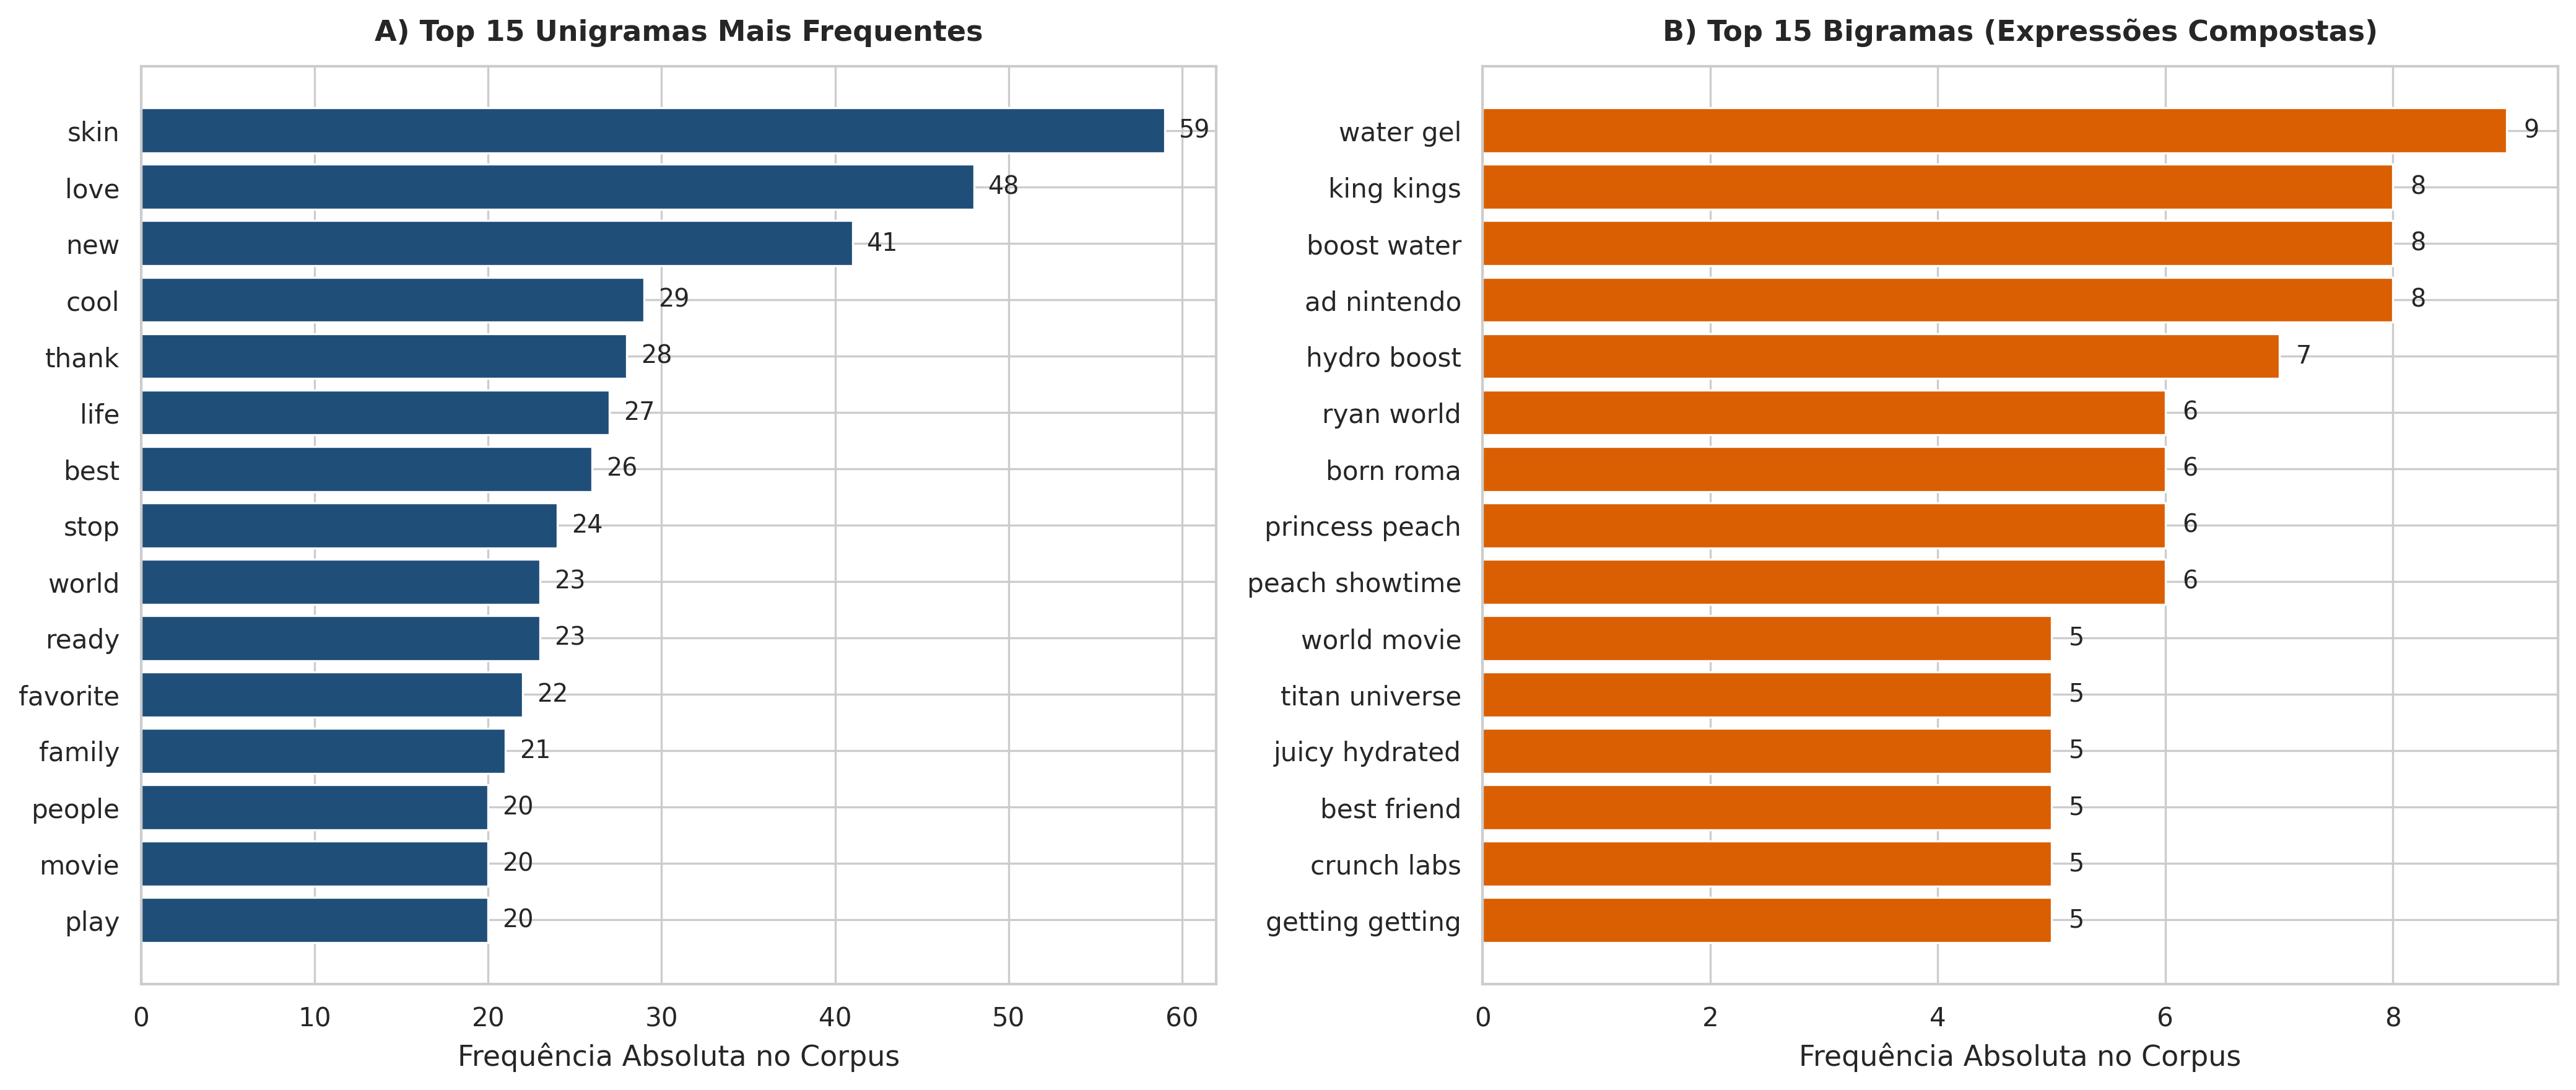

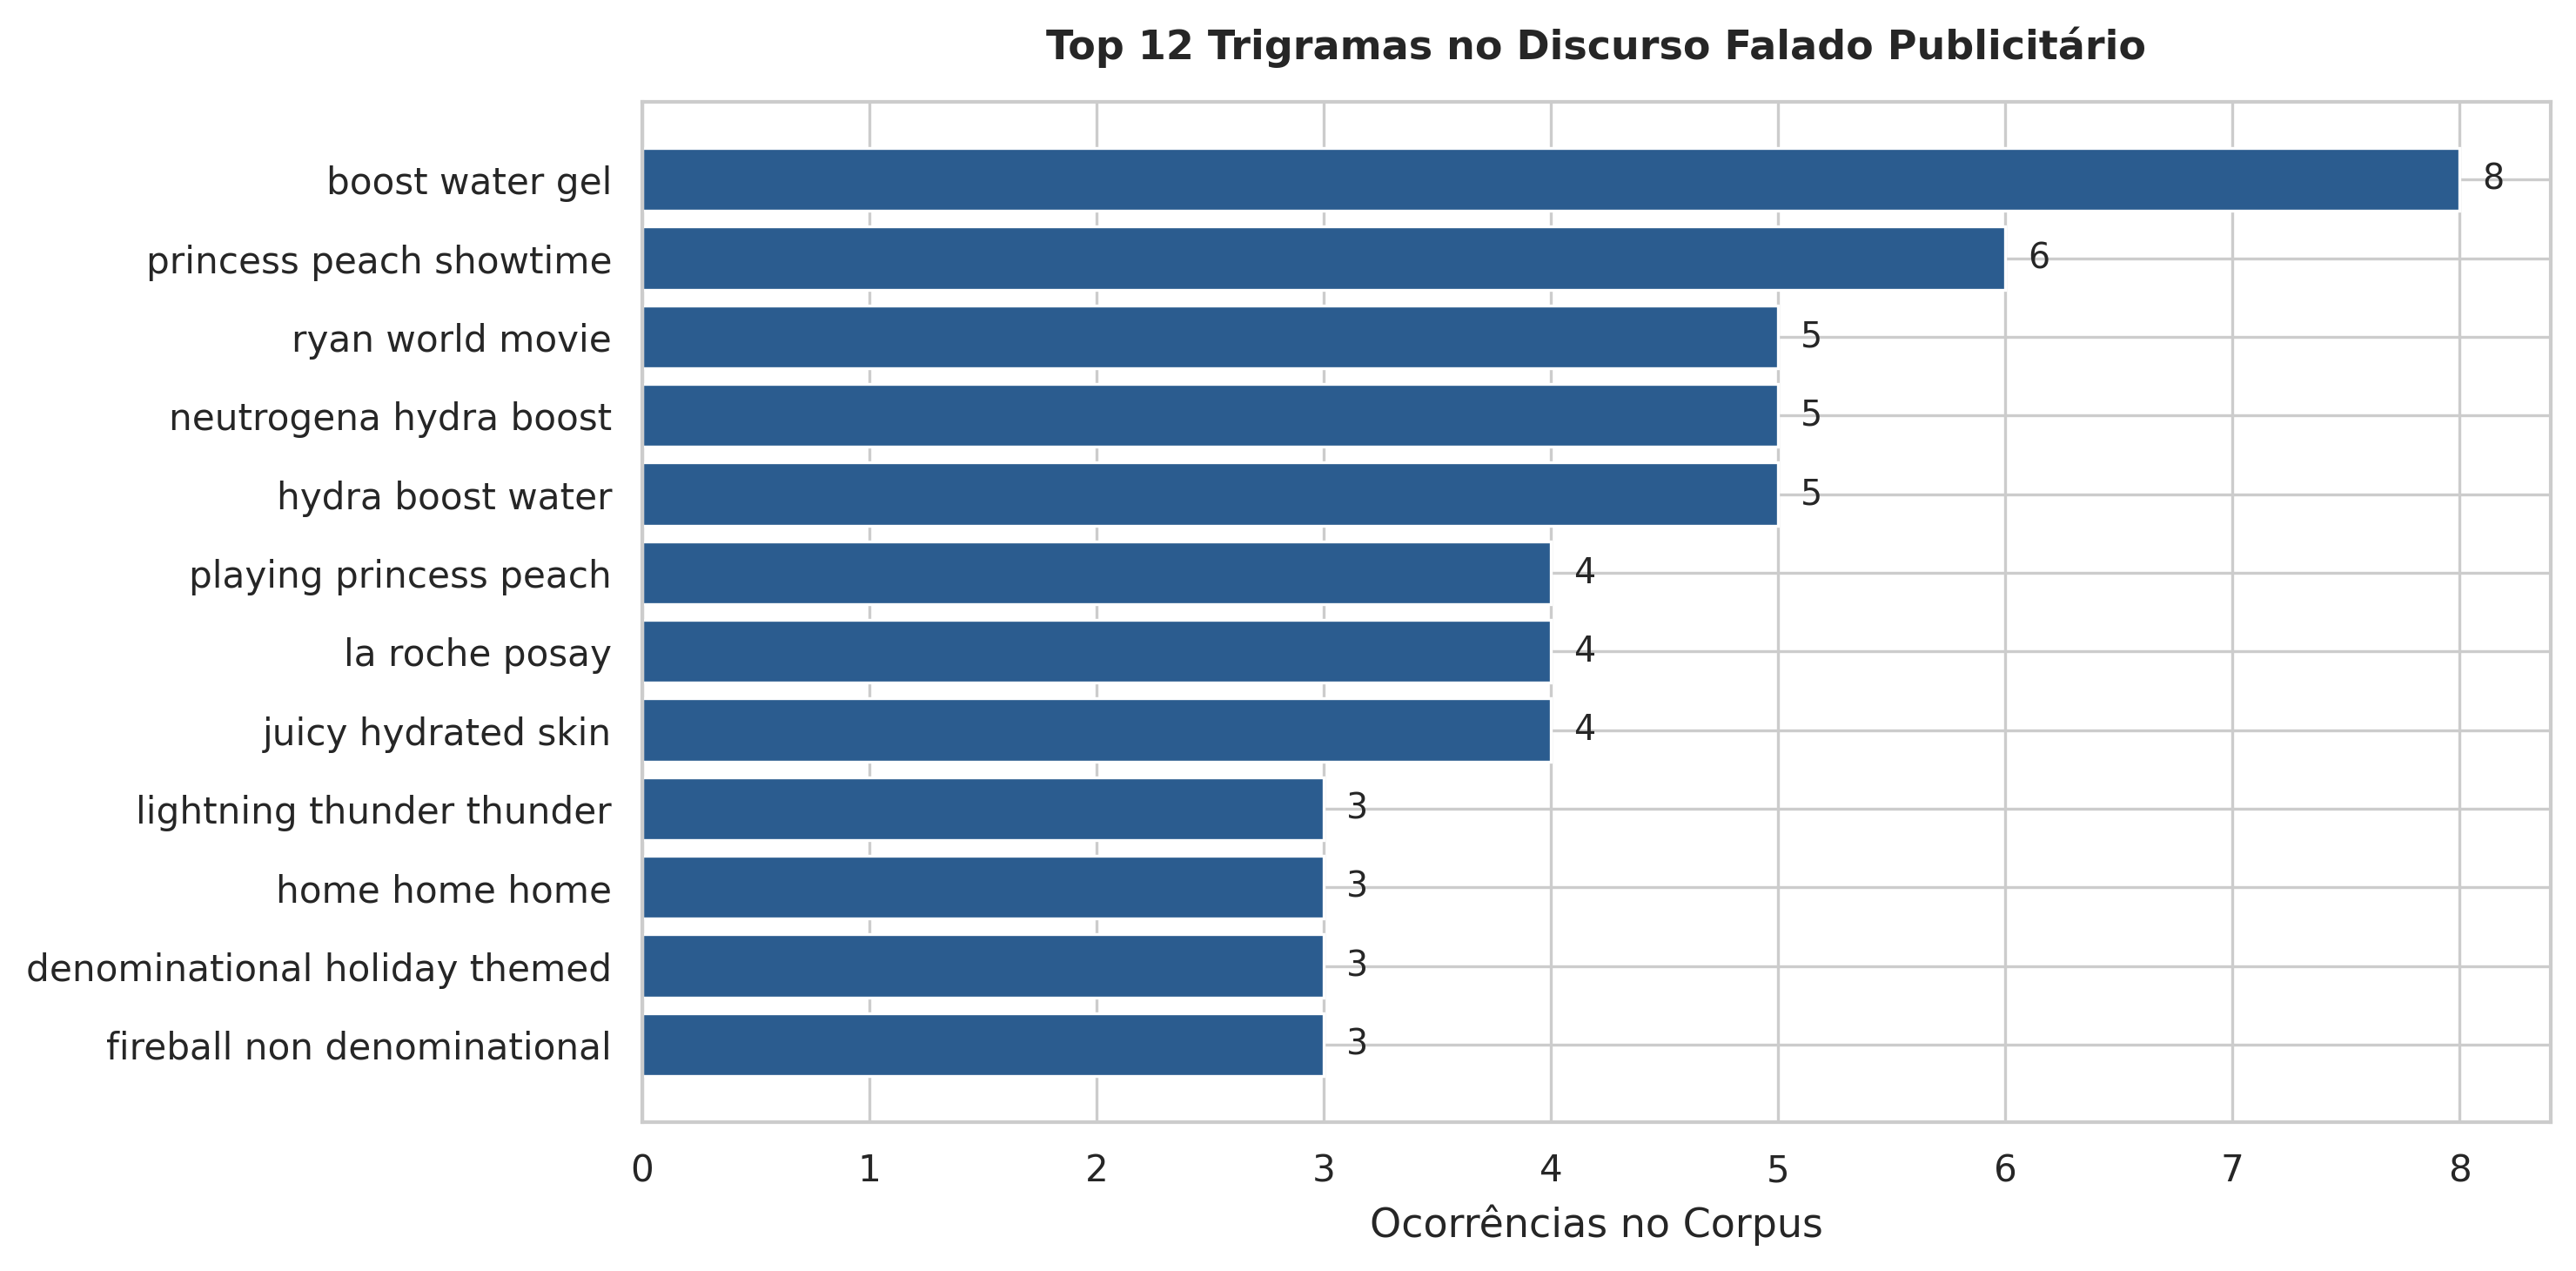

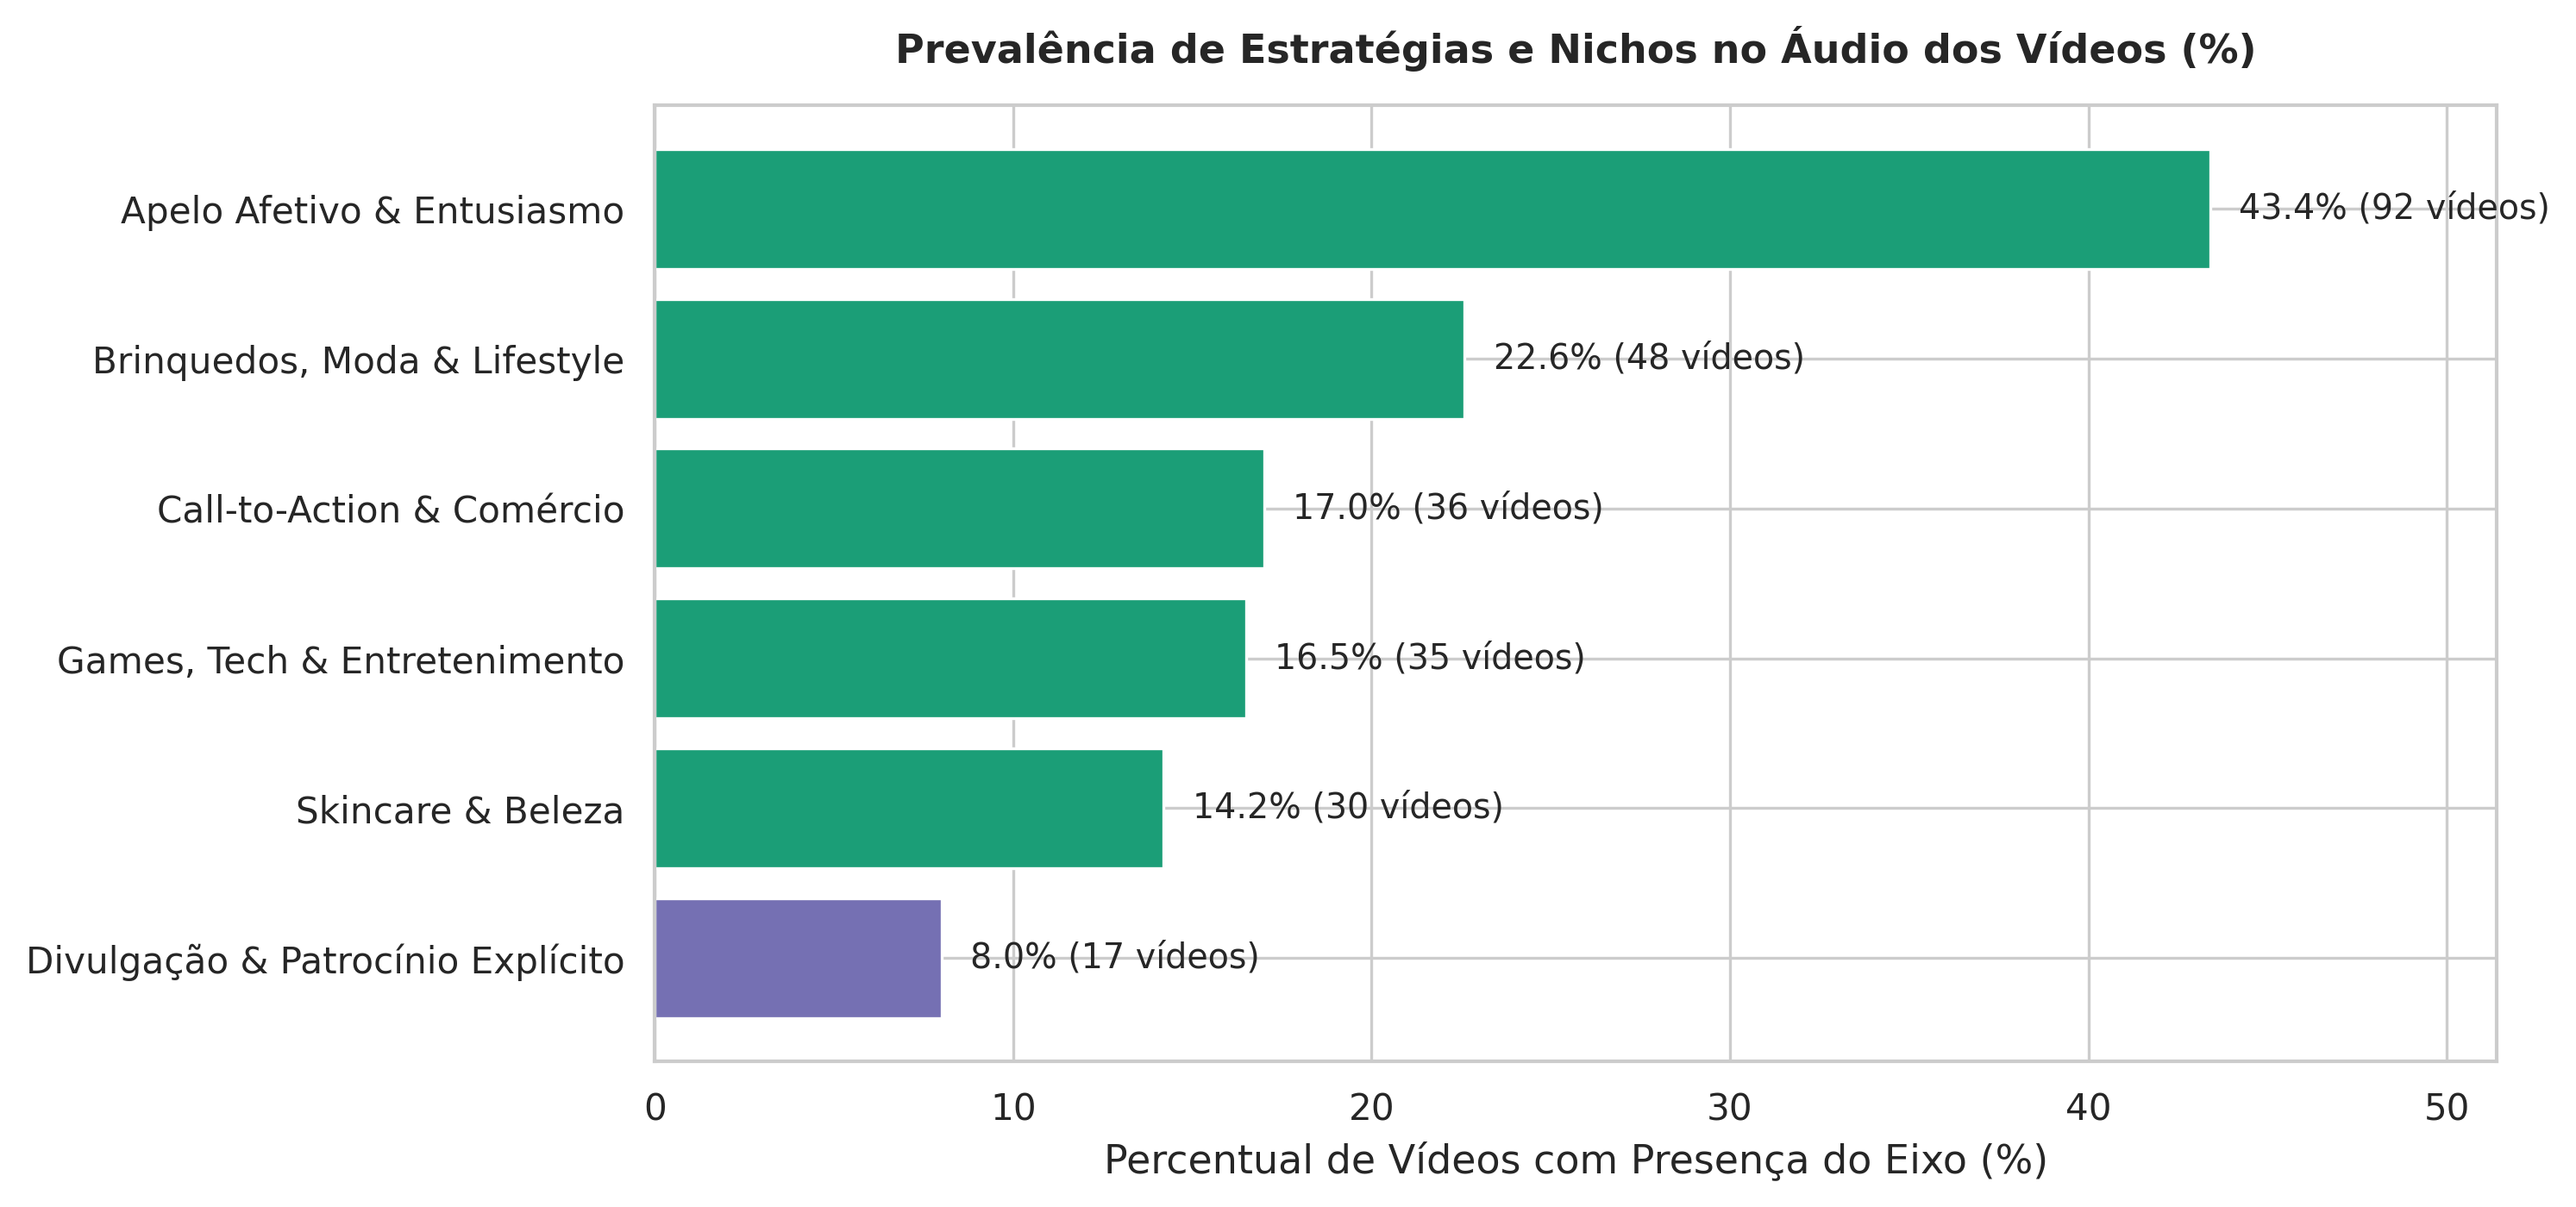

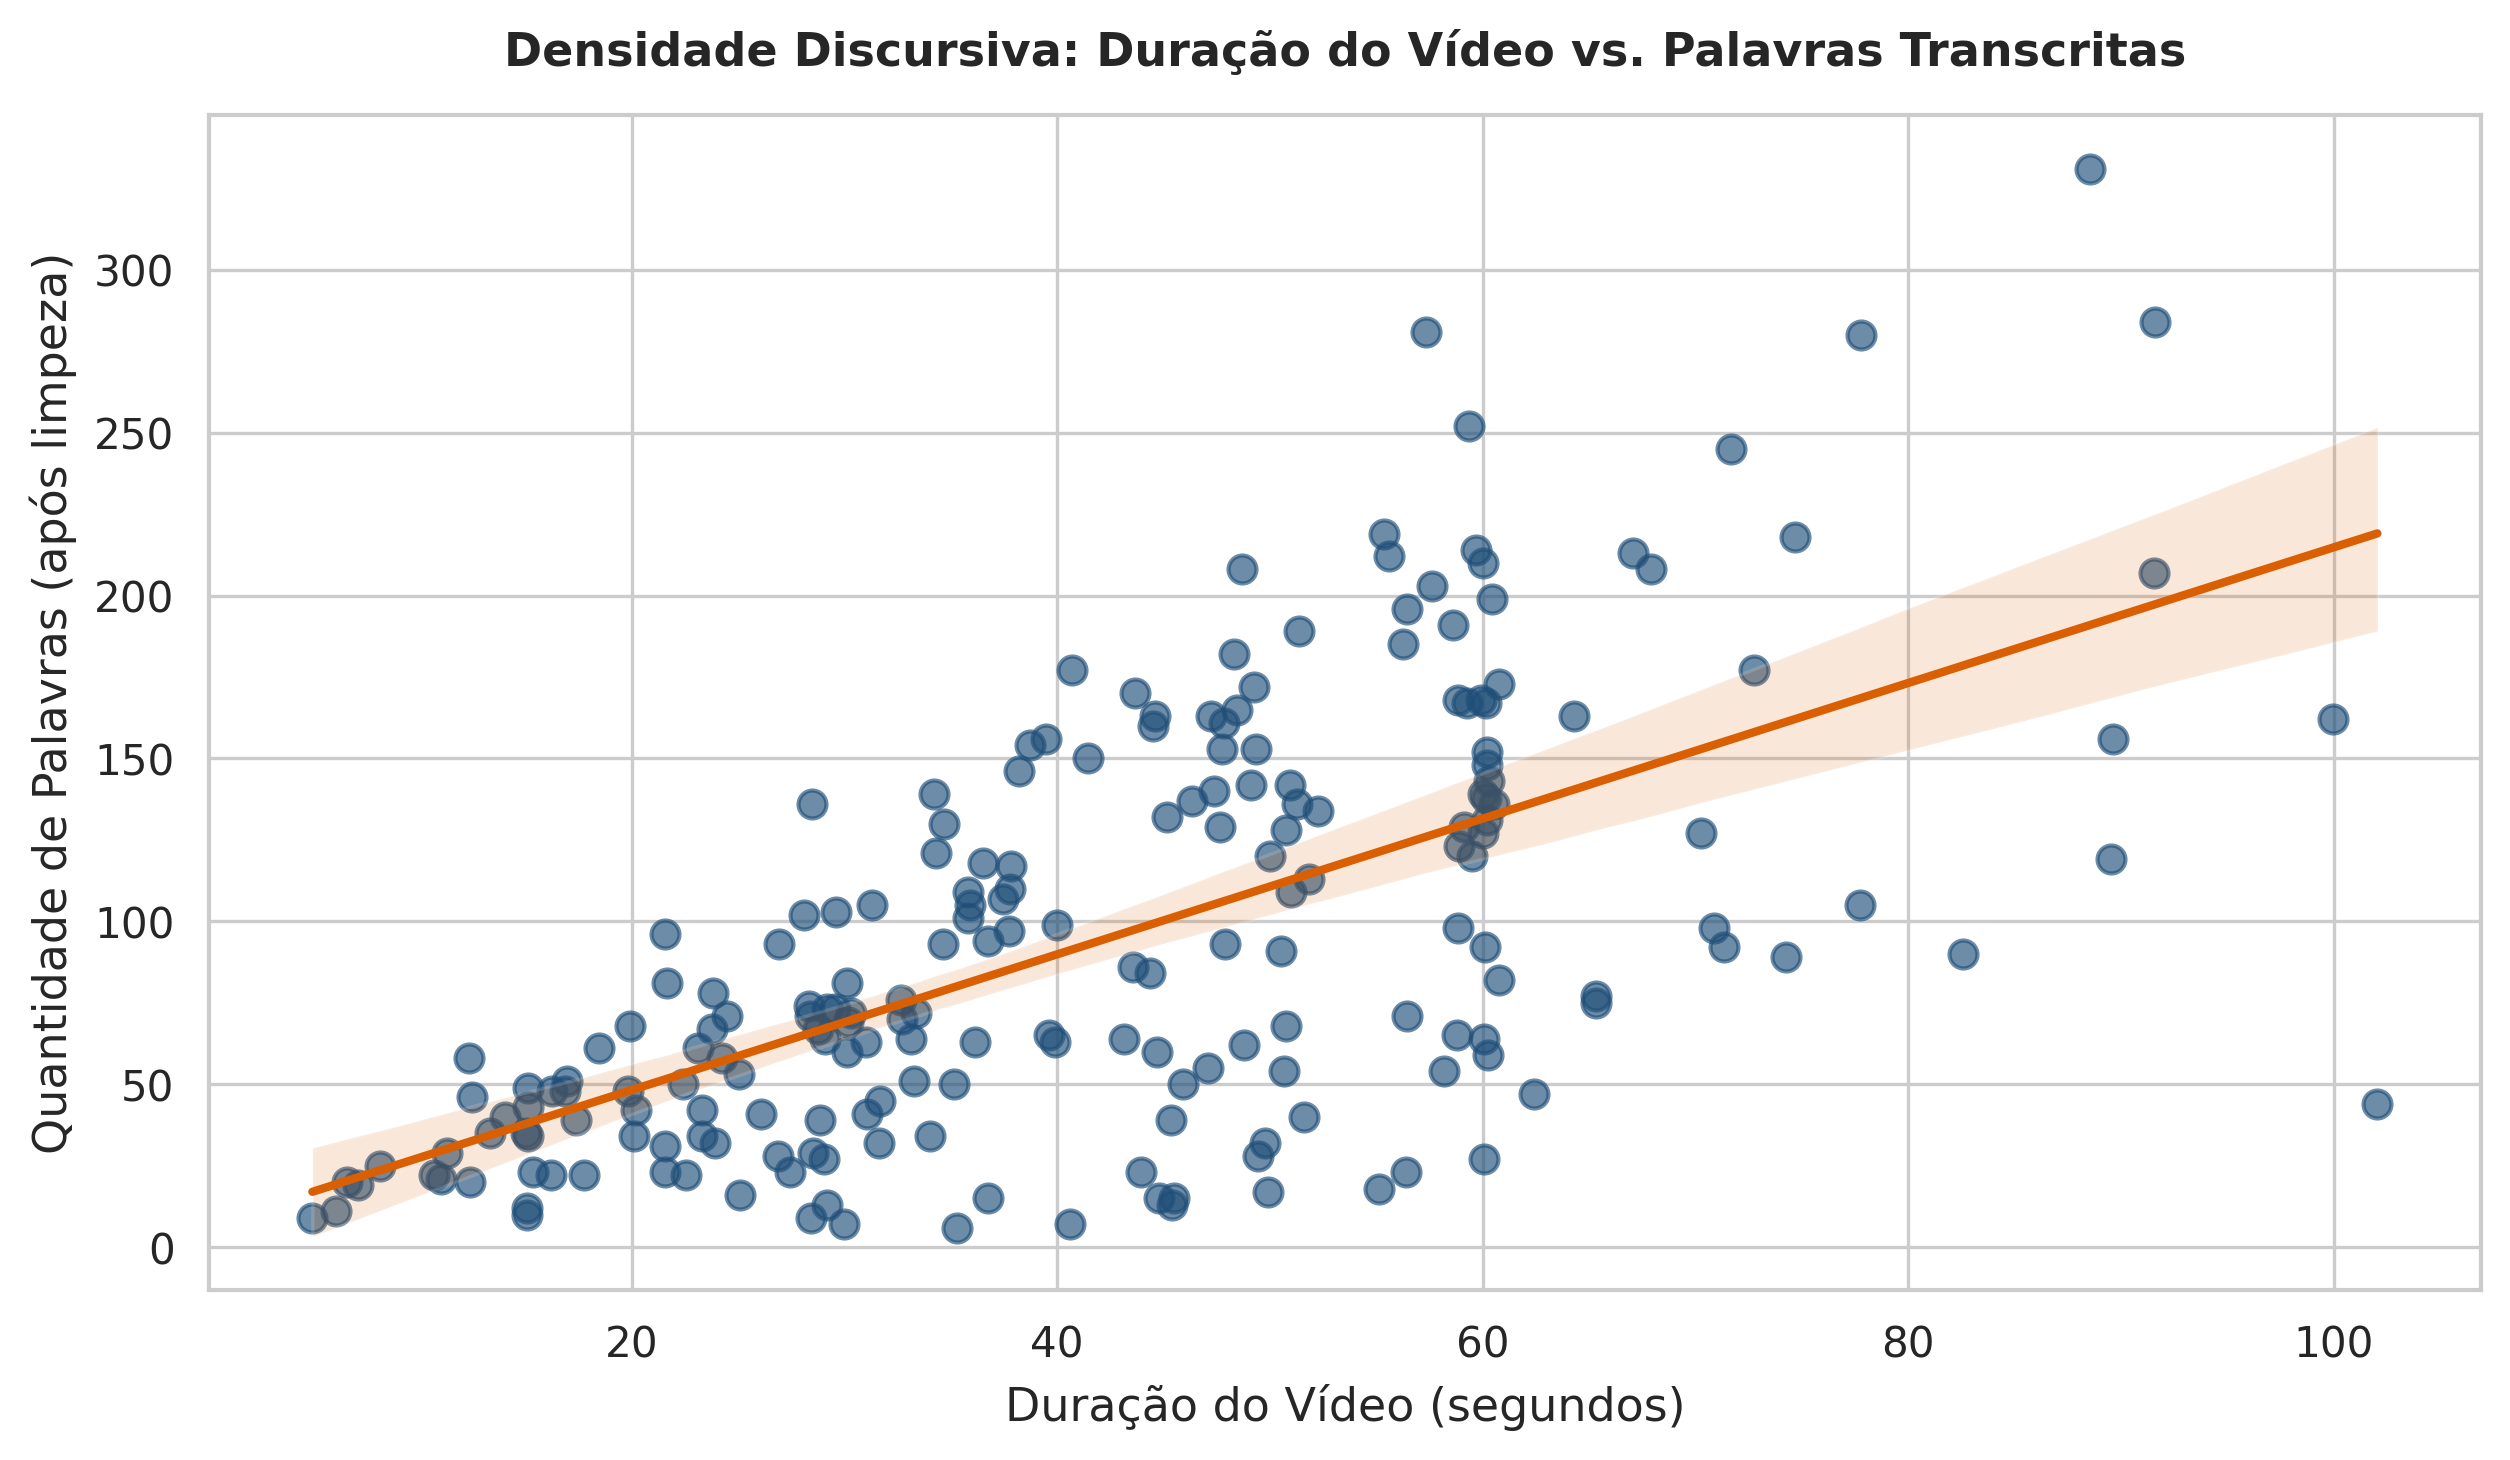

Todas as 4 figuras e tabelas foram exportadas para: /content/drive/MyDrive/resultados_etapa2


In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="paper", font_scale=1.15)
PALETA_AZUL = "#1f4e78"
PALETA_DESTAQUE = "#d95f02"

# --- FIGURA 1: Painel Duplo (Top 15 Unigramas e Top 15 Bigramas) ---
fig, axes = plt.subplots(1, 2, figsize=(14, 6), dpi=300)

top_u = df_unigramas.head(15).sort_values("ocorrencias", ascending=True)
axes[0].barh(top_u["termo"], top_u["ocorrencias"], color=PALETA_AZUL)
axes[0].set_title("A) Top 15 Unigramas Mais Frequentes", fontweight="bold", pad=10)
axes[0].set_xlabel("Frequência Absoluta no Corpus")
for i, v in enumerate(top_u["ocorrencias"]):
    axes[0].text(v + 0.8, i, str(v), va="center", fontsize=9.5)

top_b = df_bigramas.head(15).sort_values("ocorrencias", ascending=True)
axes[1].barh(top_b["termo"], top_b["ocorrencias"], color=PALETA_DESTAQUE)
axes[1].set_title("B) Top 15 Bigramas (Expressões Compostas)", fontweight="bold", pad=10)
axes[1].set_xlabel("Frequência Absoluta no Corpus")
for i, v in enumerate(top_b["ocorrencias"]):
    axes[1].text(v + 0.15, i, str(v), va="center", fontsize=9.5)

plt.tight_layout()
plt.savefig(PASTA_RESULTADOS / "fig1_unigramas_bigramas.png", dpi=300, bbox_inches="tight")
plt.show()

# --- FIGURA 2: Top 12 Trigramas ---
plt.figure(figsize=(10, 5), dpi=300)
top_t = df_trigramas.head(12).sort_values("ocorrencias", ascending=True)
bars = plt.barh(top_t["termo"], top_t["ocorrencias"], color="#2b5c8f")
plt.title("Top 12 Trigramas no Discurso Falado Publicitário", fontweight="bold", pad=12)
plt.xlabel("Ocorrências no Corpus")
for bar in bars:
    w = bar.get_width()
    plt.text(w + 0.1, bar.get_y() + bar.get_height()/2, f"{int(w)}", va="center", fontsize=9.5)
plt.tight_layout()
plt.savefig(PASTA_RESULTADOS / "fig2_trigramas.png", dpi=300, bbox_inches="tight")
plt.show()

# --- FIGURA 3: Prevalência dos Eixos Discursivos (% de Vídeos) ---
plt.figure(figsize=(10, 4.8), dpi=300)
df_cat_plot = df_categorias.sort_values("Pct_Corpus", ascending=True)
cores_cat = ["#7570b3" if "Divulgação" in c else "#1b9e77" for c in df_cat_plot["Eixo_Discursivo"]]
bars = plt.barh(df_cat_plot["Eixo_Discursivo"], df_cat_plot["Pct_Corpus"], color=cores_cat)
plt.title("Prevalência de Estratégias e Nichos no Áudio dos Vídeos (%)", fontweight="bold", pad=12)
plt.xlabel("Percentual de Vídeos com Presença do Eixo (%)")
plt.xlim(0, df_cat_plot["Pct_Corpus"].max() + 8)
for bar, qtd in zip(bars, df_cat_plot["Videos_Presentes"]):
    w = bar.get_width()
    plt.text(w + 0.8, bar.get_y() + bar.get_height()/2, f"{w:.1f}% ({qtd} vídeos)", va="center", fontsize=9.5)
plt.tight_layout()
plt.savefig(PASTA_RESULTADOS / "fig3_eixos_discursivos.png", dpi=300, bbox_inches="tight")
plt.show()

# --- FIGURA 4: Relação Duração do Vídeo vs. Volume de Palavras ---
plt.figure(figsize=(8.5, 5), dpi=300)
sns.regplot(
    data=df_analise,
    x="duracao_seg",
    y="qtd_palavras_limpa",
    scatter_kws={"alpha": 0.65, "color": PALETA_AZUL, "s": 45},
    line_kws={"color": PALETA_DESTAQUE, "linewidth": 2}
)
plt.title("Densidade Discursiva: Duração do Vídeo vs. Palavras Transcritas", fontweight="bold", pad=12)
plt.xlabel("Duração do Vídeo (segundos)")
plt.ylabel("Quantidade de Palavras (após limpeza)")
plt.tight_layout()
plt.savefig(PASTA_RESULTADOS / "fig4_duracao_vs_palavras.png", dpi=300, bbox_inches="tight")
plt.show()

print(f"Todas as 4 figuras e tabelas foram exportadas para: {PASTA_RESULTADOS}")